# FedVocabHAR Phase 5A

## Preregistered baselines for bounded-query vocabulary promotion

Phases 3D and 4C compared ranked-MNN only with its own threshold variants. Phase 5A adds the external and
reference baselines that a reviewer will expect, on the **frozen** encoders and folds that already exist:

* **RealWorld** (Phase 3B encoders, Phase 3A folds): federated clients are the *selection* subjects, exactly as in
  Phase 3D, so the `ranked_mnn` row must reproduce `phase3d_selection_results.csv` bit-for-bit. Test subjects are
  never indexed.
* **PAMAP2** (Phase 4B encoders, Phase 4A folds): clients are the *integration* subjects and evaluation uses the
  *test* subjects, as in Phase 4C. This dataset remains exploratory.

All policies share the encoder, the Phase 3D quantile calibration, the same clients, and the same four-query
budget. **Every oracle call is counted**, including calls whose answer is a known activity; no candidate is
filtered by ground truth before it is queried.

| Policy | Role |
|---|---|
| `ranked_mnn` | Locked FedVocabHAR policy |
| `random_query` | Chance floor: 4 random local clusters (20 seeds) |
| `support_only` | Same local clusters, ranked by support, **no** cross-client agreement |
| `novelty_top_b` | Active-learning style: query the 4 most novel windows |
| `component_mixture` | Fed-GCD style: per-client GMM components matched by Hungarian assignment |
| `centralized_oracle` | Upper bound: pool all client windows and cluster centrally |
| `ranked_mnn_fixed` | PAMAP2 only: Phase 4C fixed thresholds (0.25 / 0.89) for reference |

No policy, threshold, or model is selected in this notebook. Nothing here may be used to change Phase 5C.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from dataclasses import dataclass, asdict
from pathlib import Path
import json, random, warnings, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.cluster import AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import precision_recall_fscore_support
from scipy.optimize import linear_sum_assignment
from scipy.stats import binomtest

warnings.filterwarnings('ignore')

@dataclass(frozen=True)
class Config:
    project: str = '/content/drive/MyDrive/FedVocabHAR'
    seed: int = 42
    probe_per_subject_activity: int = 220
    max_candidates_per_client: int = 600
    min_local_cluster_size: int = 12
    min_agreeing_clients: int = 2
    label_query_budget: int = 4
    novelty_false_alarm_quantile: float = .02
    local_distance_quantile: float = .90
    agreement_similarity_quantile: float = .10
    random_query_seeds: int = 20
    gmm_max_components: int = 8
    bootstrap_resamples: int = 10000

CFG = Config()
PROJECT = Path(CFG.project)
OUT = PROJECT / 'artifacts' / 'phase5a'
FOLD_DIR = OUT / 'folds'
OUT.mkdir(parents=True, exist_ok=True); FOLD_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

seed_all(CFG.seed)
lock = json.loads((PROJECT / 'artifacts' / 'phase3d' / 'phase3d_policy_lock.json').read_text())
assert lock['selected_policy'] == 'ranked_mnn'
for k in ('max_candidates_per_client', 'min_local_cluster_size', 'min_agreeing_clients', 'label_query_budget',
          'novelty_false_alarm_quantile', 'local_distance_quantile', 'agreement_similarity_quantile'):
    assert getattr(CFG, k) == lock['config'][k], f'{k} differs from the Phase 3D lock'
print('device:', DEVICE); print(json.dumps(asdict(CFG), indent=2))

device: cuda
{
  "project": "/content/drive/MyDrive/FedVocabHAR",
  "seed": 42,
  "probe_per_subject_activity": 220,
  "max_candidates_per_client": 600,
  "min_local_cluster_size": 12,
  "min_agreeing_clients": 2,
  "label_query_budget": 4,
  "novelty_false_alarm_quantile": 0.02,
  "local_distance_quantile": 0.9,
  "agreement_similarity_quantile": 0.1,
  "random_query_seeds": 20,
  "gmm_max_components": 8,
  "bootstrap_resamples": 10000
}


## Frozen datasets

Each dataset record points at its cache, preregistered fold manifest, and per-fold encoder bundles. The encoder
definition below uses the Phase 4C key names; Phase 3B checkpoints use the older `block1.*` names and are mapped
with `adapt_checkpoint_keys`, so a single class serves both datasets.

In [3]:
DATASETS = {
    'realworld': dict(
        cache=PROJECT / 'data' / 'realworld' / 'cache' / 'realworld_forearm_acc_w128_s64_50hz.npz',
        manifest=PROJECT / 'artifacts' / 'phase3a' / 'phase3a_preregistered_manifest.json',
        models=PROJECT / 'artifacts' / 'phase3b' / 'folds',
        domains=lambda fold: 6,
        client_key='selection_subjects', eval_key='selection_subjects',
        limited_known_probe=True,
        reference=PROJECT / 'artifacts' / 'phase3d' / 'phase3d_selection_results.csv',
        status='Selection-only; test subjects never indexed. ranked_mnn must reproduce Phase 3D.'),
    'pamap2': dict(
        cache=PROJECT / 'data' / 'pamap2' / 'cache' / 'pamap2_hand_acc_common8_w128_s64_50hz.npz',
        manifest=PROJECT / 'artifacts' / 'phase4a_fixed3' / 'phase4a_preregistered_manifest.json',
        models=PROJECT / 'artifacts' / 'phase4b' / 'folds',
        domains=lambda fold: len(fold['train_subjects']),
        client_key='integration_subjects', eval_key='test_subjects',
        limited_known_probe=False,
        reference=PROJECT / 'artifacts' / 'phase4c' / 'phase4c_ranked_mnn_results.csv',
        status='Exploratory: test labels were opened in Phase 4B/4C.'),
}
for name, ds in DATASETS.items():
    assert ds['cache'].exists() and ds['manifest'].exists(), name
    ds['folds'] = json.loads(ds['manifest'].read_text())['outer_folds']
    for fold in ds['folds']:
        assert (ds['models'] / f"fold_{fold['fold']}_models.pt").exists(), (name, fold['fold'])

class Block(nn.Module):
    def __init__(self, channels, width=32):
        super().__init__()
        self.a = nn.Conv1d(channels, width, 1, bias=False)
        self.b = nn.ModuleList([nn.Conv1d(width, width, k, padding=k // 2, bias=False) for k in (9, 19, 39)])
        self.p = nn.Sequential(nn.MaxPool1d(3, 1, 1), nn.Conv1d(channels, width, 1, bias=False))
        self.n = nn.BatchNorm1d(4 * width)
    def forward(self, q):
        z = self.a(q)
        return F.relu(self.n(torch.cat([f(z) for f in self.b] + [self.p(q)], 1)))

class Encoder(nn.Module):
    def __init__(self, domains):
        super().__init__()
        self.b1 = Block(4); self.b2 = Block(128)
        self.s = nn.Conv1d(4, 128, 1, bias=False); self.n = nn.BatchNorm1d(128)
        self.p = nn.Sequential(nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, 64))
        self.decoder = nn.Conv1d(128, 4, 1)
        self.domain = nn.Sequential(nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, domains))
    def forward(self, q):
        z = F.relu(self.n(self.b2(self.b1(q)) + self.s(q)))
        return F.normalize(self.p(z.mean(-1)), dim=1)

def adapt_checkpoint_keys(state):
    table = [('block1.bottleneck.', 'b1.a.'), ('block1.branches.', 'b1.b.'), ('block1.pool.', 'b1.p.'), ('block1.bn.', 'b1.n.'),
             ('block2.bottleneck.', 'b2.a.'), ('block2.branches.', 'b2.b.'), ('block2.pool.', 'b2.p.'), ('block2.bn.', 'b2.n.'),
             ('skip.', 's.'), ('project.', 'p.'), ('bn.', 'n.')]
    out = {}
    for key, value in state.items():
        for old, new in table: key = key.replace(old, new)
        out[key] = value
    return out

def load(path):
    try: return torch.load(path, map_location='cpu', weights_only=False)
    except TypeError: return torch.load(path, map_location='cpu')

def unit(z): return z / (np.linalg.norm(z, axis=1, keepdims=True) + 1e-12)

def encode(model, data, batch=512):
    out = []; model.eval()
    with torch.no_grad():
        for i in range(0, len(data), batch):
            out.append(model(torch.from_numpy(data[i:i + batch]).to(DEVICE)).cpu().numpy())
    return unit(np.concatenate(out))

class Frozen:
    """Holds one dataset's windows and produces per-fold frozen embeddings."""
    def __init__(self, name):
        self.name = name; ds = DATASETS[name]; self.ds = ds
        d = np.load(ds['cache'])
        self.x = d['x'].astype(np.float32); self.subjects = d['subject'].astype(int); self.activities = d['activity'].astype(str)
        man = json.loads(ds['manifest'].read_text())
        self.known = tuple(man['known_activities']); self.novel = tuple(man['novel_activities'])
        self.vocabulary = self.known + self.novel; self.known_to_index = {a: i for i, a in enumerate(self.known)}
        self.folds = ds['folds']
    def embedding(self, fold):
        bundle = load(self.ds['models'] / f"fold_{fold['fold']}_models.pt"); st = bundle['stats']
        inp = np.concatenate([(self.x[:, :3] - st['xyz_mean']) / st['xyz_std'], (self.x[:, 3:4] - st['mag_mean']) / st['mag_std']], 1).astype(np.float32)
        m = Encoder(self.ds['domains'](fold)).to(DEVICE)
        m.load_state_dict(adapt_checkpoint_keys(bundle['anchor_state_dict']), strict=True)
        return encode(m, inp)
    def limited(self, subject_set, activity_set, n, seed):
        rng = np.random.default_rng(seed); out = []
        for s in subject_set:
            for a in activity_set:
                q = np.where((self.subjects == s) & (self.activities == a))[0]
                if len(q) > n: q = rng.choice(q, n, replace=False)
                out += q.tolist()
        return np.asarray(out, dtype=int)

## Phase 3D calibration and local discovery (verbatim)

`calibration`, `cluster`, `local`, and `mnn_groups` are the Phase 3D functions. The only change is that
dataset-specific arrays are passed through the `Frozen` object instead of module globals.

In [4]:
def calibration(D, emb, fold):
    fid = int(fold['fold']); train = tuple(fold['train_subjects']); sel = tuple(fold['selection_subjects'])
    tr = D.limited(train, D.known, CFG.probe_per_subject_activity, CFG.seed + 10 * fid)
    se = D.limited(sel, D.known, CFG.probe_per_subject_activity, CFG.seed + 10 * fid + 1)
    y = np.asarray([D.known_to_index[a] for a in D.activities[tr]])
    p = np.asarray([unit(emb[tr][y == k].mean(0, keepdims=True))[0] for k in range(len(D.known))])
    truth = np.asarray([D.known_to_index[a] for a in D.activities[se]]); score = emb[se] @ p.T
    novelty = float(np.quantile(score[np.arange(len(score)), truth], CFG.novelty_false_alarm_quantile))
    within = []; cross = []; rng = np.random.default_rng(CFG.seed + fid)
    for a in D.known:
        means = []
        for s in sel:
            q = np.where((D.subjects == s) & (D.activities == a))[0]
            if len(q) == 0: continue
            q = rng.choice(q, min(80, len(q)), replace=False); z = emb[q]
            within += (1 - z @ z.T)[np.triu_indices(len(z), 1)].tolist()
        for s in train:
            q = np.where((D.subjects == s) & (D.activities == a))[0]
            if len(q): means.append(unit(emb[q].mean(0, keepdims=True))[0])
        cross += [float(means[i] @ means[j]) for i in range(len(means)) for j in range(i + 1, len(means))]
    return p, {'novelty_threshold': novelty,
               'local_distance': float(np.quantile(within, CFG.local_distance_quantile)),
               'agreement_similarity': float(np.quantile(cross, CFG.agreement_similarity_quantile))}

def cluster(z, d):
    if len(z) < 2: return np.zeros(len(z), dtype=int)
    try: return AgglomerativeClustering(n_clusters=None, distance_threshold=d, metric='cosine', linkage='average').fit_predict(z)
    except TypeError: return AgglomerativeClustering(n_clusters=None, distance_threshold=d, affinity='cosine', linkage='average').fit_predict(z)

def ranked_windows(D, emb, p, client):
    idx = np.where(D.subjects == client)[0]; nov = 1 - (emb[idx] @ p.T).max(1)
    order = np.argsort(nov)[-min(CFG.max_candidates_per_client, len(idx)):]
    return idx[order], nov[order]

def rows_from_clusters(D, emb, windows, labels, client):
    rows = []
    for lab in np.unique(labels):
        m = np.where(labels == lab)[0]
        if len(m) < CFG.min_local_cluster_size: continue
        w = windows[m]; sig = unit(emb[w].mean(0, keepdims=True))[0]; med = w[np.argmax(emb[w] @ sig)]
        v, n = np.unique(D.activities[w], return_counts=True)
        rows.append({'client': int(client), 'signature': sig, 'support': len(w), 'medoid': int(med),
                     'query_label': str(D.activities[med]), 'dominant': str(v[np.argmax(n)]), 'purity': float(n.max() / n.sum())})
    return rows

def local(D, emb, clients, p, c, distance=None):
    rows = []
    for s in clients:
        q, _ = ranked_windows(D, emb, p, s)
        rows += rows_from_clusters(D, emb, q, cluster(emb[q], c['local_distance'] if distance is None else distance), s)
    return rows

def mnn_groups(rows, t):
    if not rows: return []
    z = np.asarray([r['signature'] for r in rows]); sim = z @ z.T; best = {}
    for i, r in enumerate(rows):
        eligible = [j for j, s in enumerate(rows) if s['client'] != r['client'] and sim[i, j] >= t]
        if eligible: best[i] = max(eligible, key=lambda j: sim[i, j])
    groups = []; seen = set()
    for i, j in best.items():
        if best.get(j) == i and tuple(sorted((i, j))) not in seen:
            groups.append(sorted((i, j))); seen.add(tuple(sorted((i, j))))
    return groups

def group_candidates(D, rows, groups, require_agreement=True):
    out = []
    for g in groups:
        members = [rows[i] for i in g]; clients = set(r['client'] for r in members)
        if require_agreement and len(clients) < CFG.min_agreeing_clients: continue
        sig = unit(np.stack([r['signature'] for r in members]).mean(0, keepdims=True))[0]
        med = max(members, key=lambda r: sig @ r['signature'])['medoid']
        out.append({'signature': sig, 'label': str(D.activities[med]), 'clients': clients,
                    'support': sum(r['support'] for r in members),
                    'purity': float(np.average([r['purity'] for r in members], weights=[r['support'] for r in members])),
                    'dominant': [r['dominant'] for r in members]})
    return out

def spend_budget(D, candidates, order_key=None):
    """Query the top-B candidates and keep novel, de-duplicated answers. Every query is counted."""
    queried = candidates if order_key is None else sorted(candidates, key=order_key, reverse=True)
    queried = queried[:CFG.label_query_budget]
    accepted = [r for r in queried if r['label'] in D.novel]; dedup = []; seen = set()
    for r in accepted:
        if r['label'] not in seen: dedup.append(r); seen.add(r['label'])
    return dedup, len(queried), [r['label'] for r in queried]

## Policies

Every policy returns `(entries, label_queries, queried_labels)` from the same `rows` (local clusters) or the
same per-client ranked windows, so differences are attributable to the association rule alone.

In [5]:
def policy_ranked_mnn(D, emb, clients, p, c, rows, seed, **_):
    return spend_budget(D, group_candidates(D, rows, mnn_groups(rows, c['agreement_similarity'])), lambda r: r['support'])

def policy_support_only(D, emb, clients, p, c, rows, seed, **_):
    cands = group_candidates(D, rows, [[i] for i in range(len(rows))], require_agreement=False)
    return spend_budget(D, cands, lambda r: r['support'])

def policy_random_query(D, emb, clients, p, c, rows, seed, **_):
    rng = np.random.default_rng(seed)
    cands = group_candidates(D, rows, [[i] for i in range(len(rows))], require_agreement=False)
    pick = rng.permutation(len(cands))[:CFG.label_query_budget] if cands else []
    return spend_budget(D, [cands[i] for i in pick])

def policy_novelty_top_b(D, emb, clients, p, c, rows, seed, **_):
    pool = []
    for s in clients:
        q, nov = ranked_windows(D, emb, p, s)
        pool += [(float(n), int(w), int(s)) for w, n in zip(q, nov)]
    pool.sort(reverse=True)
    cands = [{'signature': emb[w], 'label': str(D.activities[w]), 'clients': {s}, 'support': 1, 'purity': float('nan'), 'dominant': [str(D.activities[w])]}
             for _, w, s in pool[:CFG.label_query_budget]]
    return spend_budget(D, cands)

def policy_centralized_oracle(D, emb, clients, p, c, rows, seed, **_):
    pooled = np.concatenate([ranked_windows(D, emb, p, s)[0] for s in clients])
    central = rows_from_clusters(D, emb, pooled, cluster(emb[pooled], c['local_distance']), client=-1)
    cands = group_candidates(D, central, [[i] for i in range(len(central))], require_agreement=False)
    return spend_budget(D, cands, lambda r: r['support'])

def policy_component_mixture(D, emb, clients, p, c, rows, seed, **_):
    comp_rows = []
    for s in clients:
        q, _ = ranked_windows(D, emb, p, s)
        k_local = max(1, sum(1 for r in rows if r['client'] == s)); k = int(min(CFG.gmm_max_components, max(2, k_local), max(2, len(q) // CFG.min_local_cluster_size)))
        gmm = GaussianMixture(n_components=k, covariance_type='diag', random_state=seed, n_init=1, reg_covar=1e-4).fit(emb[q])
        comp_rows += rows_from_clusters(D, emb, q, gmm.predict(emb[q]), s)
    groups = []; by_client = {}
    for i, r in enumerate(comp_rows): by_client.setdefault(r['client'], []).append(i)
    cl = sorted(by_client)
    for a in range(len(cl)):
        for b in range(a + 1, len(cl)):
            ia, ib = by_client[cl[a]], by_client[cl[b]]
            sim = np.asarray([[comp_rows[i]['signature'] @ comp_rows[j]['signature'] for j in ib] for i in ia])
            ri, ci = linear_sum_assignment(-sim)
            groups += [[ia[i], ib[j]] for i, j in zip(ri, ci) if sim[i, j] >= c['agreement_similarity']]
    return spend_budget(D, group_candidates(D, comp_rows, groups), lambda r: r['support'])

def policy_ranked_mnn_fixed(D, emb, clients, p, c, rows, seed, **_):
    rows_fixed = local(D, emb, clients, p, c, distance=.25)
    return spend_budget(D, group_candidates(D, rows_fixed, mnn_groups(rows_fixed, .89)), lambda r: r['support'])

POLICIES = {
    'ranked_mnn': policy_ranked_mnn, 'random_query': policy_random_query, 'support_only': policy_support_only,
    'novelty_top_b': policy_novelty_top_b, 'component_mixture': policy_component_mixture, 'centralized_oracle': policy_centralized_oracle,
}
REFERENCE_ONLY = {'pamap2': {'ranked_mnn_fixed': policy_ranked_mnn_fixed}}

## Evaluation

Known prototypes come from training subjects only. RealWorld uses the Phase 3D limited probe
(220 windows per subject-activity, seed `42 + 500 + fold`) so `ranked_mnn` reproduces Phase 3D exactly;
PAMAP2 uses all training known windows as in Phase 4C.

In [6]:
def evaluate(D, emb, fold, entries):
    fid = int(fold['fold']); train = tuple(fold['train_subjects'])
    if D.ds['limited_known_probe']:
        known_idx = D.limited(train, D.known, CFG.probe_per_subject_activity, CFG.seed + 500 + fid)
    else:
        known_idx = np.where(np.isin(D.subjects, train) & np.isin(D.activities, D.known))[0]
    y = np.asarray([D.known_to_index[a] for a in D.activities[known_idx]])
    kp = np.asarray([unit(emb[known_idx][y == k].mean(0, keepdims=True))[0] for k in range(len(D.known))])
    eval_idx = np.where(np.isin(D.subjects, tuple(fold[D.ds['eval_key']])))[0]
    labels = list(D.known) + [r['label'] for r in entries]; proto = np.asarray([*kp] + [r['signature'] for r in entries])
    pred = np.asarray(labels)[(emb[eval_idx] @ proto.T).argmax(1)]
    f = precision_recall_fscore_support(D.activities[eval_idx], pred, labels=list(D.vocabulary), zero_division=0)[2]
    nk = len(D.known)
    return {'known_macro_f1': float(f[:nk].mean()), 'novel_macro_f1': float(f[nk:].mean()), 'combined_macro_f1': float(f.mean())}

def summarize(D, entries, queries, queried_labels, metrics, extra=None):
    row = {'promoted_entries': len(entries), 'label_queries': queries,
           'novel_recovery': len(set(r['label'] for r in entries)) / len(D.novel),
           'entry_purity': float(np.nanmean([r['purity'] for r in entries])) if entries else 0.,
           'known_label_queries': sum(1 for l in queried_labels if l in D.known),
           'wasted_queries': queries - len(entries)}
    row.update(metrics); row.update(extra or {}); return row

## Run all folds for both datasets

Per-fold JSON files make the run resumable. `random_query` is averaged over 20 seeds within each fold; the
per-seed rows are kept for the dispersion plot.

In [7]:
for dname in DATASETS:
    D = Frozen(dname); print(f'== {dname}: {D.ds["status"]}')
    policies = dict(POLICIES); policies.update(REFERENCE_ONLY.get(dname, {}))
    for fold in D.folds:
        fid = int(fold['fold']); path = FOLD_DIR / f'{dname}_fold_{fid}_complete.json'
        if path.exists(): print(' fold', fid, 'already complete'); continue
        clients = tuple(fold[D.ds['client_key']])
        if dname == 'realworld':
            assert set(fold['test_subjects']).isdisjoint(clients) and set(fold['test_subjects']).isdisjoint(fold['train_subjects'])
        emb = D.embedding(fold); p, c = calibration(D, emb, fold); rows = local(D, emb, clients, p, c)
        results = []; audit = []
        for name, fn in policies.items():
            seeds = range(CFG.random_query_seeds) if name == 'random_query' else [0]
            for s in seeds:
                entries, queries, queried_labels = fn(D, emb, clients, p, c, rows, seed=CFG.seed + 1000 * fid + s)
                assert queries <= CFG.label_query_budget
                row = {'dataset': dname, 'fold': fid, 'policy': name, 'seed': s, 'local_signatures': len(rows)}
                row.update(summarize(D, entries, queries, queried_labels, evaluate(D, emb, fold, entries)))
                results.append(row)
                for k, e in enumerate(entries, 1):
                    audit.append({'dataset': dname, 'fold': fid, 'policy': name, 'seed': s, 'entry': k, 'label': e['label'],
                                  'clients': ','.join(map(str, sorted(e['clients']))), 'support': e['support'], 'purity': e['purity'],
                                  'queried_labels': '|'.join(queried_labels)})
        path.write_text(json.dumps({'fold': fold, 'calibration': c, 'results': results, 'entries': audit}, indent=2))
        print(' completed fold', fid)

== realworld: Selection-only; test subjects never indexed. ranked_mnn must reproduce Phase 3D.
 completed fold 1
 completed fold 2
 completed fold 3
 completed fold 4
 completed fold 5
== pamap2: Exploratory: test labels were opened in Phase 4B/4C.
 completed fold 1
 completed fold 2
 completed fold 3
 completed fold 4


## Reproduction guard

The RealWorld `ranked_mnn` rows must equal the Phase 3D lock; the PAMAP2 `ranked_mnn_fixed` rows must equal
Phase 4C. If either assertion fails, the pipeline has drifted and nothing below may be reported.

In [8]:
payloads = [json.loads(p.read_text()) for p in sorted(FOLD_DIR.glob('*_complete.json'))]
results = pd.DataFrame([r for p in payloads for r in p['results']])
entries = pd.DataFrame([r for p in payloads for r in p['entries']])
results.to_csv(OUT / 'phase5a_results_per_seed.csv', index=False); entries.to_csv(OUT / 'phase5a_promoted_entries.csv', index=False)

ref3d = pd.read_csv(DATASETS['realworld']['reference']); ref3d = ref3d[ref3d.policy == 'ranked_mnn'].set_index('fold')
ours = results[(results.dataset == 'realworld') & (results.policy == 'ranked_mnn')].set_index('fold')
for col in ('label_queries', 'novel_recovery', 'entry_purity', 'novel_macro_f1'):
    assert np.allclose(ours[col].sort_index(), ref3d[col].sort_index(), atol=1e-6), f'RealWorld ranked_mnn {col} drifted from Phase 3D'
print('RealWorld ranked_mnn reproduces Phase 3D.')

ref4c = pd.read_csv(DATASETS['pamap2']['reference']).set_index('fold')
ours = results[(results.dataset == 'pamap2') & (results.policy == 'ranked_mnn_fixed')].set_index('fold')
# Phase 4C filtered known-label candidates before budgeting, so only promoted entries and F1 are comparable.
for col in ('promoted_entries', 'novel_recovery', 'novel_macro_f1', 'combined_macro_f1'):
    ok = np.allclose(ours[col].sort_index(), ref4c[col].sort_index(), atol=1e-6)
    print(f'PAMAP2 ranked_mnn_fixed {col}: {"matches" if ok else "DIFFERS (expected only if a known-label candidate outranked a novel one)"} Phase 4C')

RealWorld ranked_mnn reproduces Phase 3D.
PAMAP2 ranked_mnn_fixed promoted_entries: matches Phase 4C
PAMAP2 ranked_mnn_fixed novel_recovery: matches Phase 4C
PAMAP2 ranked_mnn_fixed novel_macro_f1: DIFFERS (expected only if a known-label candidate outranked a novel one) Phase 4C
PAMAP2 ranked_mnn_fixed combined_macro_f1: DIFFERS (expected only if a known-label candidate outranked a novel one) Phase 4C


## Fold-level aggregation, bootstrap intervals, and paired comparisons

In [9]:
METRICS = ['novel_macro_f1', 'combined_macro_f1', 'known_macro_f1', 'novel_recovery', 'entry_purity', 'label_queries', 'promoted_entries', 'known_label_queries']
fold_level = results.groupby(['dataset', 'fold', 'policy'])[METRICS].mean().reset_index()
fold_level.to_csv(OUT / 'phase5a_fold_results.csv', index=False)

def boot_ci(v, n=CFG.bootstrap_resamples, seed=CFG.seed):
    v = np.asarray(v, dtype=float); v = v[~np.isnan(v)]
    if len(v) == 0: return (float('nan'), float('nan'))
    rng = np.random.default_rng(seed); m = rng.choice(v, (n, len(v)), replace=True).mean(1)
    return float(np.quantile(m, .025)), float(np.quantile(m, .975))

summary_rows = []
for (dname, pol), g in fold_level.groupby(['dataset', 'policy']):
    row = {'dataset': dname, 'policy': pol, 'folds': len(g)}
    for m in METRICS:
        lo, hi = boot_ci(g[m]); row[m] = float(np.nanmean(g[m])); row[m + '_ci_lo'] = lo; row[m + '_ci_hi'] = hi
    summary_rows.append(row)
summary = pd.DataFrame(summary_rows).sort_values(['dataset', 'novel_macro_f1'], ascending=[True, False])
summary.to_csv(OUT / 'phase5a_summary.csv', index=False)

paired_rows = []
for dname, g in fold_level.groupby('dataset'):
    base = g[g.policy == 'ranked_mnn'].set_index('fold')
    for pol, h in g.groupby('policy'):
        if pol == 'ranked_mnn': continue
        h = h.set_index('fold').loc[base.index]
        for m in ('novel_macro_f1', 'combined_macro_f1', 'novel_recovery', 'entry_purity', 'label_queries'):
            d = (base[m] - h[m]).values; wins = int((d > 0).sum()); ties = int((d == 0).sum()); n = len(d) - ties
            pval = float(binomtest(wins, n, .5, alternative='greater').pvalue) if n > 0 else float('nan')
            lo, hi = boot_ci(d)
            paired_rows.append({'dataset': dname, 'baseline': pol, 'metric': m, 'mean_diff_ranked_minus_baseline': float(d.mean()),
                                'ci_lo': lo, 'ci_hi': hi, 'folds_ranked_better': wins, 'folds_tied': ties, 'folds': len(d), 'sign_test_p_greater': pval})
paired = pd.DataFrame(paired_rows); paired.to_csv(OUT / 'phase5a_paired_vs_ranked_mnn.csv', index=False)
display(summary.round(4)); display(paired.round(4))

,dataset,policy,folds,novel_macro_f1,novel_macro_f1_ci_lo,novel_macro_f1_ci_hi,combined_macro_f1,combined_macro_f1_ci_lo,combined_macro_f1_ci_hi,known_macro_f1,...,entry_purity_ci_hi,label_queries,label_queries_ci_lo,label_queries_ci_hi,promoted_entries,promoted_entries_ci_lo,promoted_entries_ci_hi,known_label_queries,known_label_queries_ci_lo,known_label_queries_ci_hi
3,pamap2,random_query,4,0.1579,0.1135,0.2230,0.3756,0.3248,0.4175,0.5933,...,0.4964,3.25,3.00,3.75,1.75,1.25,2.00,0.75,0.25,1.00
6,pamap2,support_only,4,0.1513,0.1078,0.2258,0.3727,0.3122,0.4209,0.5942,...,0.3987,3.25,3.00,3.75,1.75,1.25,2.00,0.75,0.25,1.00
2,pamap2,novelty_top_b,4,0.0955,0.0774,0.1134,0.3322,0.2860,0.3784,0.5688,...,NaN,4.00,4.00,4.00,1.00,1.00,1.00,0.25,0.00,0.75
0,pamap2,centralized_oracle,4,0.0749,0.0220,0.1162,0.3346,0.2633,0.3975,0.5944,...,0.4878,2.00,1.25,2.75,0.75,0.25,1.00,1.25,0.50,2.00
4,pamap2,ranked_mnn,4,0.0713,0.0232,0.1115,0.3232,0.2486,0.3977,0.5750,...,0.3094,0.75,0.25,1.00,0.75,0.25,1.00,0.00,0.00,0.00
5,pamap2,ranked_mnn_fixed,4,0.0711,0.0232,0.1129,0.3235,0.2510,0.3959,0.5758,...,0.3374,0.75,0.25,1.00,0.75,0.25,1.00,0.00,0.00,0.00
1,pamap2,component_mixture,4,0.0343,0.0000,0.0716,0.2908,0.2481,0.3360,0.5473,...,0.3410,1.00,0.25,1.75,0.50,0.00,1.00,0.50,0.00,1.00
7,realworld,centralized_oracle,5,0.2721,0.1220,0.4223,0.4830,0.4019,0.5665,0.6938,...,0.7059,3.80,3.40,4.00,2.00,1.20,2.80,1.60,1.00,2.40
11,realworld,ranked_mnn,5,0.2460,0.1048,0.3727,0.4700,0.3862,0.5510,0.6941,...,0.8210,3.60,2.80,4.00,1.60,0.60,2.40,1.80,1.20,2.40
8,realworld,component_mixture,5,0.2375,0.1750,0.2823,0.4604,0.4117,0.5008,0.6833,...,0.8192,4.00,4.00,4.00,2.40,2.00,2.80,1.00,0.40,1.60


,dataset,baseline,metric,mean_diff_ranked_minus_baseline,ci_lo,ci_hi,folds_ranked_better,folds_tied,folds,sign_test_p_greater
0,pamap2,centralized_oracle,novel_macro_f1,-0.0035,-0.0641,0.0494,2,1,4,0.5000
1,pamap2,centralized_oracle,combined_macro_f1,-0.0115,-0.0531,0.0175,2,0,4,0.6875
2,pamap2,centralized_oracle,novel_recovery,0.0000,-0.1875,0.1875,1,2,4,0.7500
3,pamap2,centralized_oracle,entry_purity,-0.0602,-0.4100,0.2025,3,0,4,0.3125
4,pamap2,centralized_oracle,label_queries,-1.2500,-2.5000,-0.2500,0,1,4,1.0000
5,pamap2,component_mixture,novel_macro_f1,0.0370,-0.0014,0.0950,2,1,4,0.5000
6,pamap2,component_mixture,combined_macro_f1,0.0323,0.0005,0.0910,3,1,4,0.1250
7,pamap2,component_mixture,novel_recovery,0.0625,0.0000,0.1875,1,3,4,0.5000
8,pamap2,component_mixture,entry_purity,0.0462,-0.0458,0.1994,1,1,4,0.8750
9,pamap2,component_mixture,label_queries,-0.2500,-0.7500,0.0000,0,3,4,1.0000


## Figures and decision record

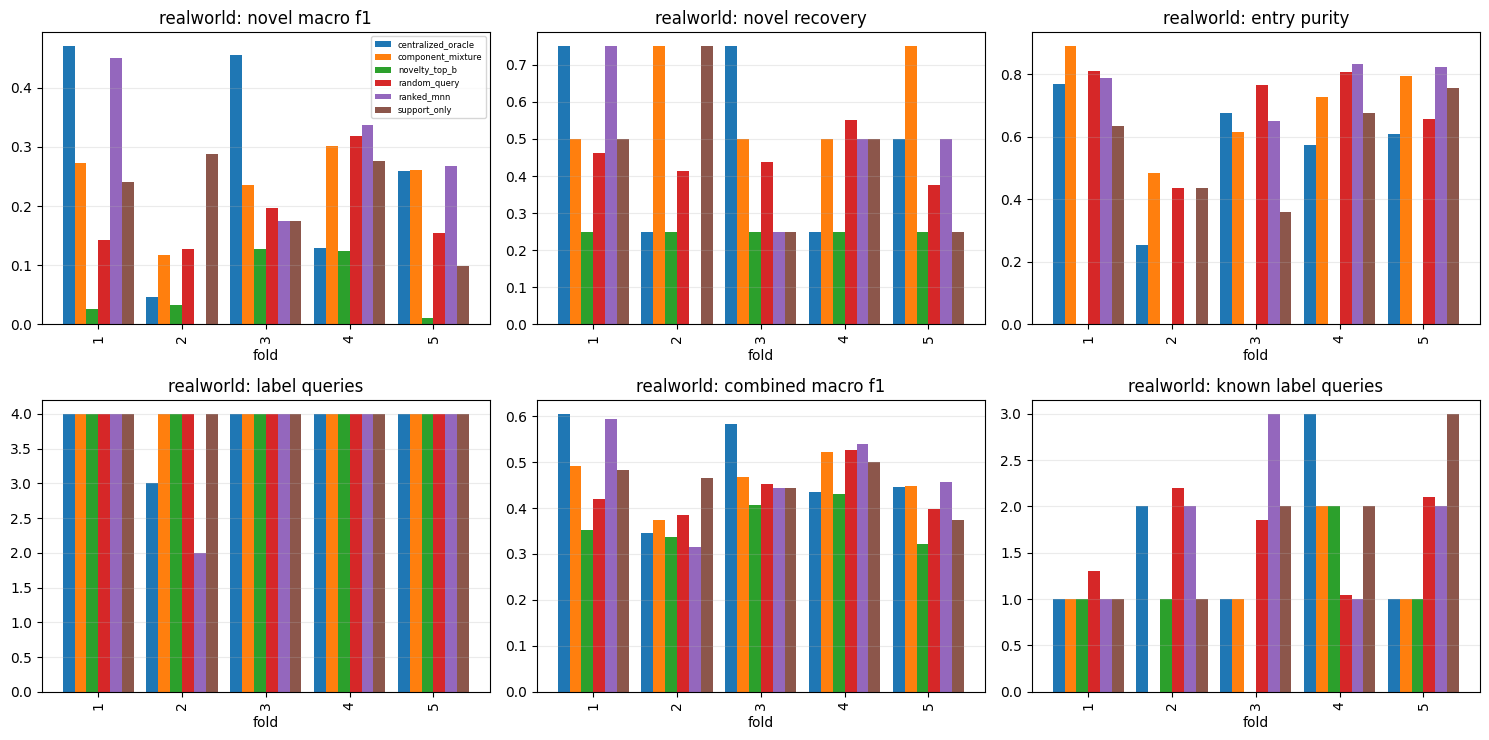

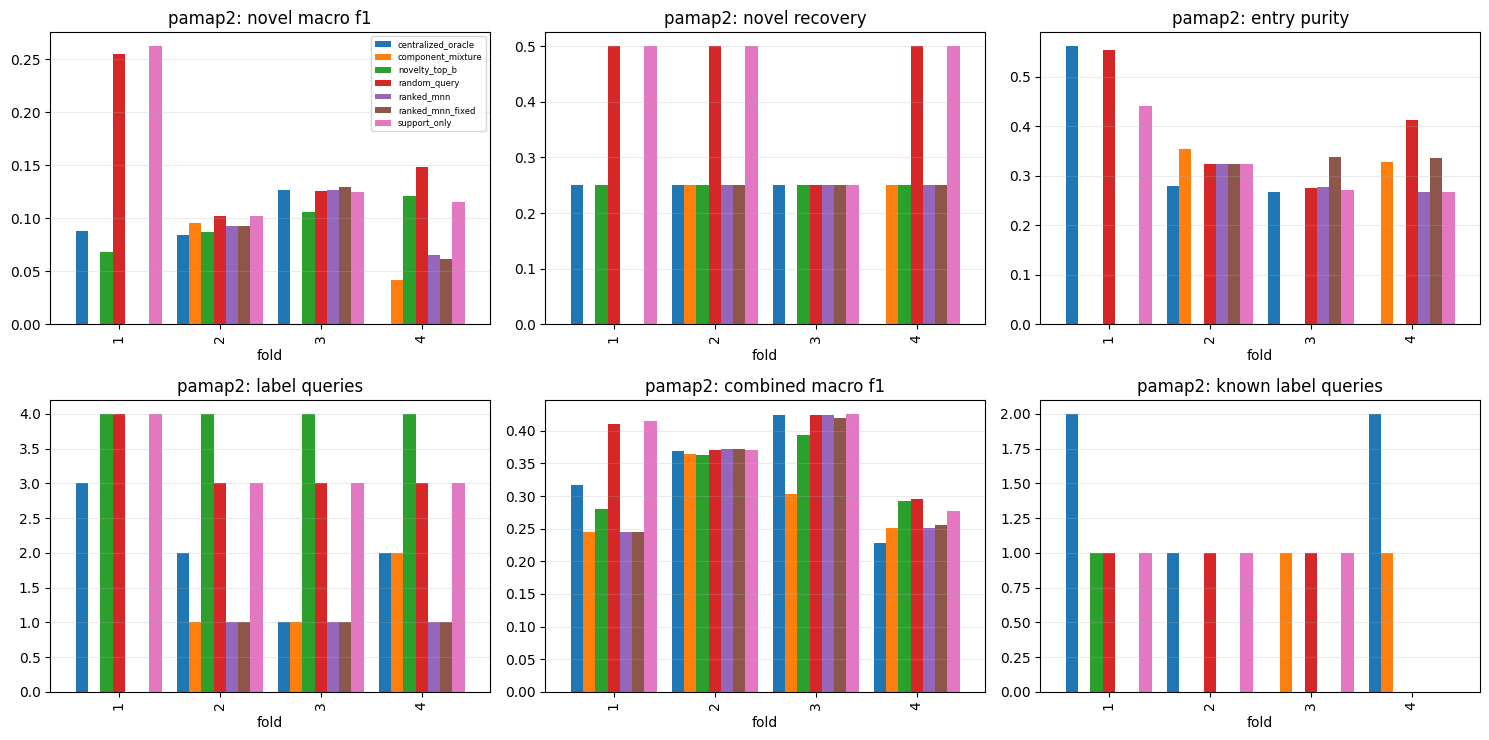

# FedVocabHAR Phase 5A Baselines

All policies share frozen encoders, Phase 3D calibration, clients, and a four-query budget. Every oracle call is counted.

## realworld

Selection-only; test subjects never indexed. ranked_mnn must reproduce Phase 3D.

| Policy | Novel F1 [95% CI] | Combined F1 | Recovery | Purity | Queries | Known-label queries |
|---|---|---|---|---|---|---|
| centralized_oracle | 0.2721 [0.122, 0.422] | 0.4830 | 0.500 | 0.577 | 3.80 | 1.60 |
| ranked_mnn | 0.2460 [0.105, 0.373] | 0.4700 | 0.400 | 0.620 | 3.60 | 1.80 |
| component_mixture | 0.2375 [0.175, 0.282] | 0.4604 | 0.600 | 0.702 | 4.00 | 1.00 |
| support_only | 0.2157 [0.152, 0.274] | 0.4531 | 0.450 | 0.573 | 4.00 | 1.80 |
| random_query | 0.1881 [0.139, 0.256] | 0.4363 | 0.447 | 0.697 | 4.00 | 1.70 |
| novelty_top_b | 0.0638 [0.021, 0.107] | 0.3693 | 0.250 | nan | 4.00 | 1.00 |

### Paired differences (ranked_mnn minus baseline)

| Baseline | Metric | Mean diff [95% CI] | Folds ranked better | Sign-test p |


In [10]:
PLOT = ['novel_macro_f1', 'novel_recovery', 'entry_purity', 'label_queries', 'combined_macro_f1', 'known_label_queries']
for dname in DATASETS:
    g = fold_level[fold_level.dataset == dname]
    fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
    for ax, m in zip(axes.ravel(), PLOT):
        g.pivot(index='fold', columns='policy', values=m).plot(kind='bar', ax=ax, width=.85)
        ax.set_title(f'{dname}: {m.replace("_", " ")}'); ax.grid(axis='y', alpha=.25); ax.set_xlabel('fold')
        ax.legend(fontsize=6) if m == PLOT[0] else ax.get_legend().remove()
    fig.tight_layout(); fig.savefig(OUT / f'phase5a_{dname}_baselines.png', dpi=180, bbox_inches='tight'); plt.show()

decision = {
    'phase': 'Phase 5A', 'status': 'Baseline comparison on frozen encoders and locked policy. No selection, tuning, or redesign occurred.',
    'query_accounting': 'All oracle calls counted, including known-label answers.',
    'datasets': {k: v['status'] for k, v in DATASETS.items()},
    'summary': json.loads(summary.set_index(['dataset', 'policy']).to_json(orient='index')),
    'paired_vs_ranked_mnn': json.loads(paired.to_json(orient='records')),
    'config': asdict(CFG)}
(OUT / 'phase5a_decision.json').write_text(json.dumps(decision, indent=2))

report = '# FedVocabHAR Phase 5A Baselines\n\nAll policies share frozen encoders, Phase 3D calibration, clients, and a four-query budget. Every oracle call is counted.\n\n'
for dname in DATASETS:
    report += f'## {dname}\n\n{DATASETS[dname]["status"]}\n\n| Policy | Novel F1 [95% CI] | Combined F1 | Recovery | Purity | Queries | Known-label queries |\n|---|---|---|---|---|---|---|\n'
    for _, r in summary[summary.dataset == dname].iterrows():
        report += (f"| {r.policy} | {r.novel_macro_f1:.4f} [{r.novel_macro_f1_ci_lo:.3f}, {r.novel_macro_f1_ci_hi:.3f}] | {r.combined_macro_f1:.4f} | "
                   f"{r.novel_recovery:.3f} | {r.entry_purity:.3f} | {r.label_queries:.2f} | {r.known_label_queries:.2f} |\n")
    report += '\n### Paired differences (ranked_mnn minus baseline)\n\n| Baseline | Metric | Mean diff [95% CI] | Folds ranked better | Sign-test p |\n|---|---|---|---|---|\n'
    for _, r in paired[paired.dataset == dname].iterrows():
        report += f"| {r.baseline} | {r.metric} | {r.mean_diff_ranked_minus_baseline:+.4f} [{r.ci_lo:+.3f}, {r.ci_hi:+.3f}] | {r.folds_ranked_better}/{r.folds} | {r.sign_test_p_greater:.3f} |\n"
    report += '\n'
(OUT / 'FedVocabHAR_Phase5A_Baselines.md').write_text(report); print(report)

## Next step

Phase 5A results are descriptive. They may be reported alongside Phases 3D and 4C but may not be used to alter
the Phase 5C preregistration, which was committed before this notebook was run.